# Mall Customer Segmentation Using K-Means Clustering

## 1. Business Context & Objective
sebuah pusat perbelanjaan (mall) memiliki data dasar pelanggan seperti usia, jenis kelamin, pendapatan tahunan, dan skor pengeluaran (spending score). saat ini, tim marketing belum memiliki pengelompokan pelanggan yang terstruktur sehingga kampanye promosi masih bersifat umum.

**Tujuan proyek:**
- mengindentifikasi segmen pelanggan yang berbeda berdasarkan perilaku belanja dan profil demografinya.
- memberikan rekomendasi strategi pemasaran yang spesifik dan tepat sasaran untuk setiap segmen pelanggan.

## 2. Dataset Overview
Dataset diambil dari [Kaggle: Mall Customer Segmentation Data](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) (`Mall_Customers.csv`) yang terdiri dari 200 data pelanggan dan 5 fitur:
- `CustomerID`: ID unik pelanggan (tidak digunakan dalam modeling)
- `Gender`: Jenis kelamin (`Male` / `Female`)
- `Age`: Usia pelanggan
- `Annual Income (k$)`: Pendapatan tahunan dalam ribuan dolar
- `Spending Score (1-100)`: Skor yang diberikan oleh pihak mall berdasarkan perilaku & tingkat pengeluaran pelanggan

## 3. Methodology
1. **Data Understanding & Cleaning:** Pemeriksaan missing values, duplikat, dan distribusi data.
2. **Exploratory Data Analysis (EDA):** Analisis univariat dan bivariat untuk melihat pola awal antar fitur.
3. **Preprocessing:** Seleksi fitur dan standarisasi skala data menggunakan `StandardScaler`.
4. **Optimal Cluster Selection:** Penentuan nilai $K$ optimal menggunakan **Elbow Method** dan **Silhouette Score**.
5. **K-Means Clustering & Profiling:** Pembangunan model, interpretasi tiap klaster menjadi persona bisnis, dan perumusan rekomendasi.

## 4. Key Insights & Customer Personas
*(Isi tabel ini setelah model K-Means selesai dijalankan)*

| Cluster | Nama Persona | Karakteristik Utama | Jumlah Pelanggan |
| :--- | :--- | :--- | :--- |
| 0 | [Misal: Careful High-Earners] | [Pendapatan tinggi, skor belanja rendah] | [...] |
| 1 | [Misal: VIP / Target Utama] | [Pendapatan tinggi, skor belanja tinggi] | [...] |
| ... | ... | ... | ... |

## 5. Business Recommendations
- **[Nama Persona 1]:** [Rekomendasi promo/strategi, misal: program VIP loyalty card]
- **[Nama Persona 2]:** [Rekomendasi promo/strategi, misal: diskon bundling atau kampanye personal]



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Pengaturan visual agar grafik lebih rapi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,5)

In [4]:
# 1. Load Dataset
df = pd.read_csv("Mall_Customers.csv")

In [5]:
# 2. Sanity check (Inspeksi Awal)
print("=== 5 Baris Pertama ===")
display(df.head())

print ("\n=== Informasi Tipe Data & Non-Null ===")
df.info()

print("\n=== statistik deskriptif ===")
display(df.describe())

=== 5 Baris Pertama ===


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



=== Informasi Tipe Data & Non-Null ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

=== statistik deskriptif ===


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


##### Pembahasan 
terdapat 200 pelanggan dengan lima variabel yang menggambarkan identitias, demografi, pendapatan, dan perilaku belanja pelanggan.

Interpretasi statistik deskriptif:
1. Age: Rata-rata usia pelanggan adalah sekitar 39 tahun. Pelanggan termuda berusia 18 tahun dan tertua 70 tahun.
2. Annual Income: Rata-rata pendapatan tahunan pelanggan adalah 60,56 ribu USD. Pendapatan terendah 15 ribu USD dan tertinggi 137 ribu USD.
3. Spending Score: Rata-rata skor pengeluaran adalah 50,2 dari 100. Ini menunjukkan bahwa rata-rata skor pengeluaran berada di sekitar titik tengah skala.

In [6]:
# 3. Cek Kualitas Data
print("\n=== Missing Values ===")
print(df.isnull().sum())

print(f"\nJumlah Baris Duplikat: {df.duplicated().sum()}")


=== Missing Values ===
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah Baris Duplikat: 0


#### Interpretasi: 
dataset tidak memiliki missing values maupun data duplikat. Dengan demikian, tidak diperlukan proses imputasi missing values atau penghapusan baris duplikasi pada tahap awal.

#### setelah memastikan datanya bersih, lanjutkan dengan visualisasi EDA
tujuannya adalah mengekplorasi pola dan hubungan antarvariabel sebelum menentukan fitur yang akan digunakan dalam K-Means

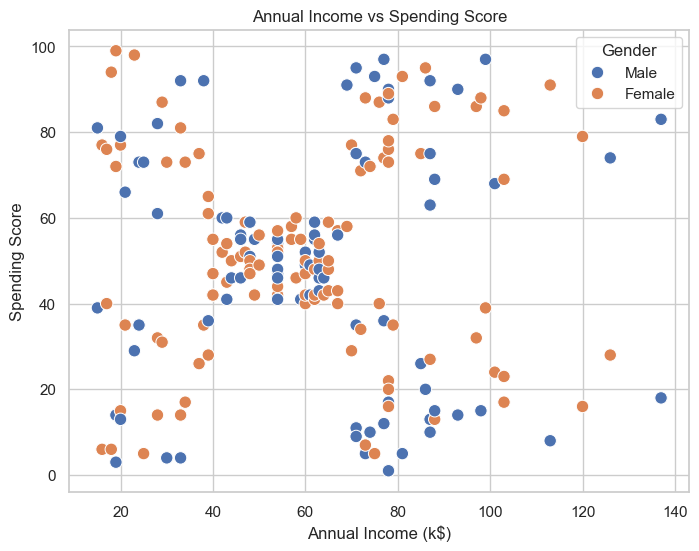

In [7]:
# 1. Scatter plot Income vs Spending Score
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    s=80
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')

plt.show()

#### Interpretasi Scatter plot
1. kiri bawah (Income rendah, spending rendah): orang yang hemat/ pelit (pendapatan kecil, pengeluaran kecil).
2. kiri atas (income rendah, spending tinggi): orang yang impulsif (pendapatan pas-pasan tapi suka belanja/jajan).
3. tengah (income sedang, spending sedang): kelompok mayoritas, orang kebanyakan.
4. kanan bawah (Income tinggi, spending rendah): orang kaya tapi hemat (atau smart shopper).
5. kanan atas (income tinggi, spending tinggi):orang kaya yang suka belanja (target utama marketing/VIP)

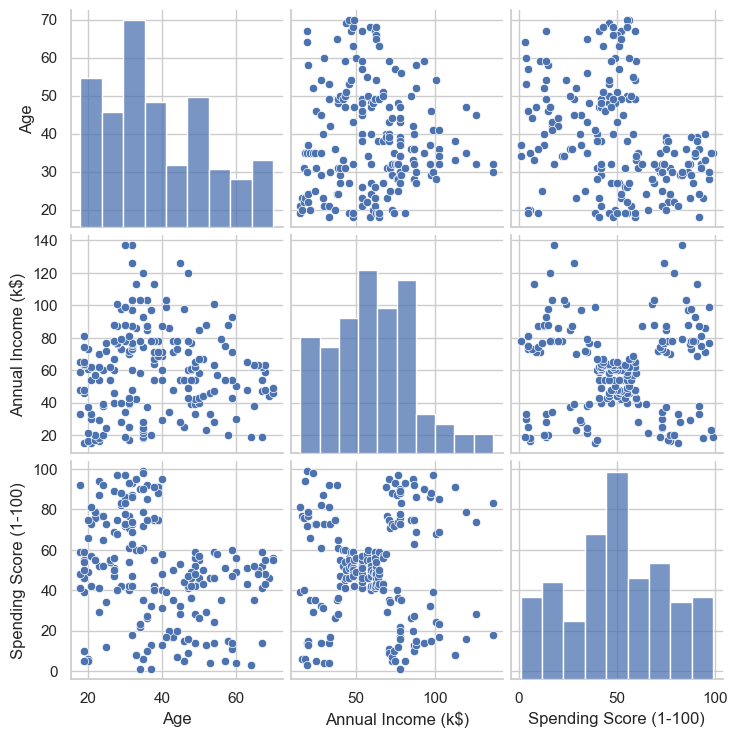

In [8]:
# 2. Pairplot (opsional, untuk melihat semua kombinasi fitur)
sns.pairplot(df.drop(columns=['CustomerID']), diag_kind='hist')
plt.show()

#### Interpretasi Pairplot
- Age vs Income/ Age vs Spending: titik-titiknya menyebar relatif acak. tidak ada pola garis atau kurva yang jelas. ini artinya umur tidak terlalu memisahkan kelompok. baik anak muda maupun orang tua bisa masuk ke cluster mana saja.
-Income vs Spending: ini adalah plot yang paling penting. di sinilah terlihat plot paling teratur dan terpisah (mirip dengan grafik pertama).
- distribusi (histogram di diagonal): data Income dan Spending cukup menyebar, sedangkan age agak skewwed (menumpuk di usia muda, yaitu 20-40 tahun).

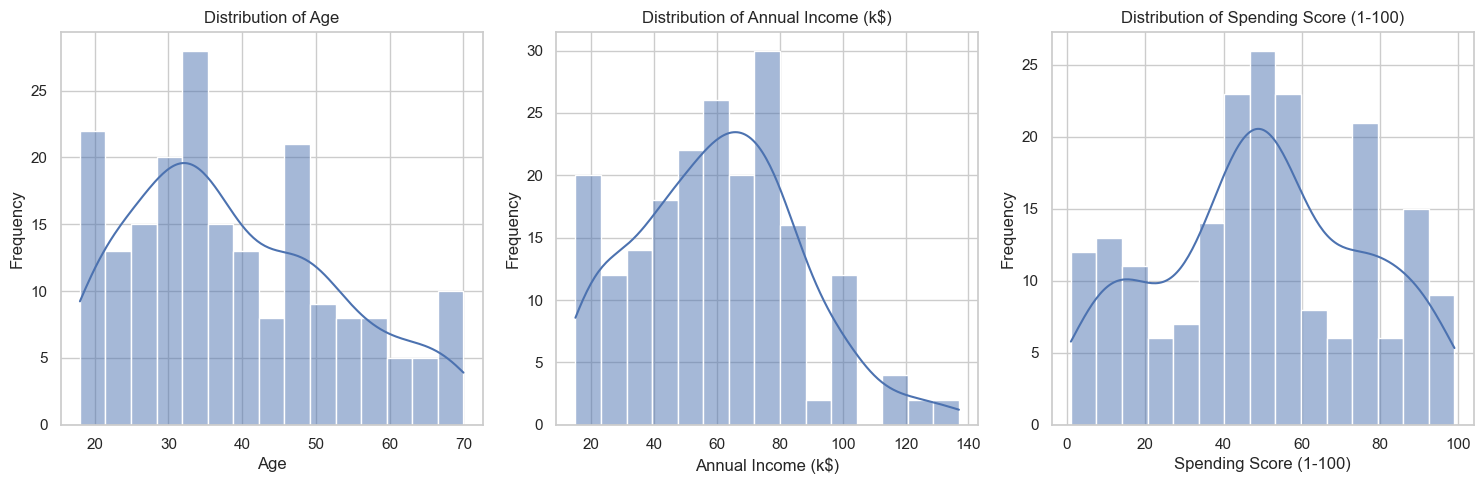

In [9]:
# Menentukan variabel numerik
numeric_cols = [
    'Age',
    'Annual Income (k$)',
    'Spending Score (1-100)'
]

# Visualisasi distribusi
plt.figure(figsize=(15, 5))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df[col], kde=True, bins=15)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


#### Interpretasi
Analisis univariat menunjukkan bahwa fitur Age memiliki distribusi righ skewed (mayoritas pelanggan berusia muda). Sementara itu, annual Income dan spending Score menujukkan distribusi bimodal (memiliki dua puncak). pola bimodal ini menjadi indikasi awal yang kuat bahwa terdapat segmentasi alami di dalam data pelanggan, yang mendukung penggunaan algoritma K-Means untuk mengelompokkan mereka berdasarkan Income dan Spending score

Gender
Female    112
Male       88
Name: count, dtype: int64


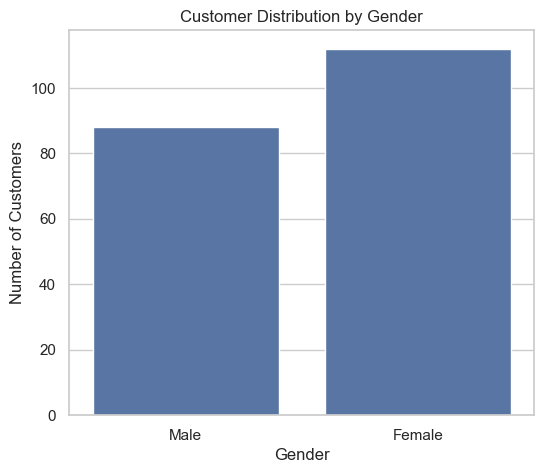

In [10]:

# Menghitung jumlah pelanggan berdasarkan gender
print(df['Gender'].value_counts())

# Visualisasi
plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='Gender')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()


#### Interpretasi
Ternyata Cluster VIP didominasi oleh perempuan (65%), ini insight bagus untuk tim marketing

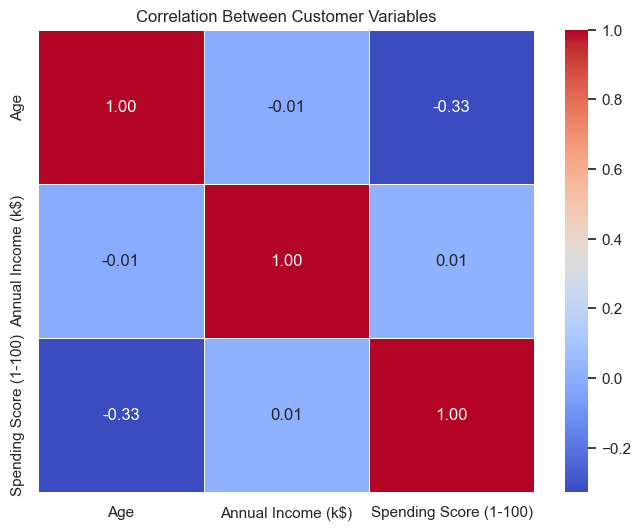

In [11]:
# Menghitung korelasi
correlation = df[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].corr()

# Visualisasi heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Customer Variables')

plt.show()


#### Hasil dan cara untuk membaca output
- Age vs Annual Income dengan korelasi -0.01 artinya, hampir tidak ada hubungan. usia tidak memprediksi pendapatan.
- Annual Income vs Spending Score d engan korelasi 0.01 artinya, hampir tidak ada hubungan. Pendapatan tinggi belum tentu belanja banyak.
- Age vs Spending score dengan korelasi -0.33 hubungan negatif yang lemah sampai sedang. Cenderung, makin tua usia, makin rendah skor belanja.

## Preprocessing

In [13]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [14]:
# 1. Seleksi fitur
# Kita hanya mengambil 2 fitur yang paling kuat berdasarkan EDA
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

In [15]:
# 2. Standarisasi (Scaling)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Mari kita cek perubahannya
# Kita butuh hasilnya ke Dataframe agar mudah dilihat
X_scaled_df = pd.DataFrame(X_scaled, columns=['Income_Scaled', 'Spending_Scaled'])

print("=== Data Asli (Sebelum Scaling) ===")
print(X.head())
print("\n=== Data Setelah Scalling ===")
print(X_scaled_df.head())

=== Data Asli (Sebelum Scaling) ===
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

=== Data Setelah Scalling ===
   Income_Scaled  Spending_Scaled
0      -1.738999        -0.434801
1      -1.738999         1.195704
2      -1.700830        -1.715913
3      -1.700830         1.040418
4      -1.662660        -0.395980


In [16]:
# Cek apakah mean sudah mendekati 0 dan std mendekati 1
print("\n=== Cek Statistik Setelah Scaling ===")
print(X_scaled_df.describe().loc[['mean', 'std']])


=== Cek Statistik Setelah Scaling ===
      Income_Scaled  Spending_Scaled
mean  -2.131628e-16    -1.465494e-16
std    1.002509e+00     1.002509e+00


## Optimal Cluster Selection

##### kita tidak akan menebak jumlah cluster (misal "ah, kelihatannya ada 5"). Kita akan membuktikannya secara matematis menggunakan dua metode:
1. Elbow Method: Melihat grafik di mana penurunan nilai inertia mulai melandai (seperti siku tangan).
2. Silhouettte Score: Mengukur seberapa padat dan terpisah cluster yang terbentuk (semakin mendekati 1, semakin bagus)

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [18]:
# 1. Menyiapkan list untuk menampung hasil 
inertia = []
silhouette_scores = []
K_range = range (2, 11) # menguji K dari 2 sampai 10

In [19]:
# 2. Looping untuk menghitung Inertia dan Silhouette
for k in K_range:
    # Menggunakan random_state agar hasilnya konsisten
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)

    # Hitung inertia (untuk Elbow)
    inertia.append(kmeans.inertia_)

    # Hitung Silhouette Score
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

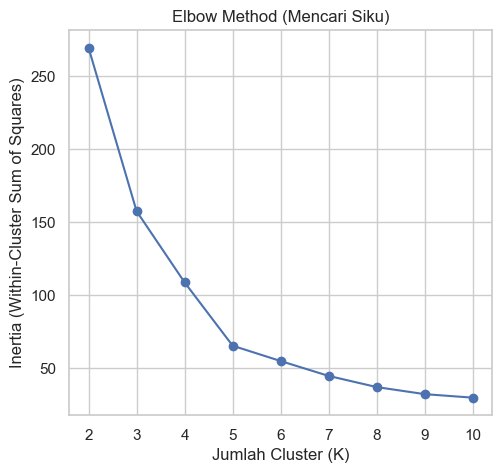

In [20]:
# 3. Visualisasi Elbow Method
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Elbow Method (Mencari Siku)')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.grid(True)


#### Hasil
- garis menurun sangat tajam dari K=2 ke K=4.
- Mulai dari K=4 ke K=5, penurunan masih cukup terlihat.
- titik "siku" (elbow) mulai terlihat jelas di K=5. setelah K=5, garisnya melandai (penurunan inersia tidak lagi signifikan.) ini menandakan penambahan cluster setelah angka 5 tidak memberi dampak besar.

<function matplotlib.pyplot.show(close=None, block=None)>

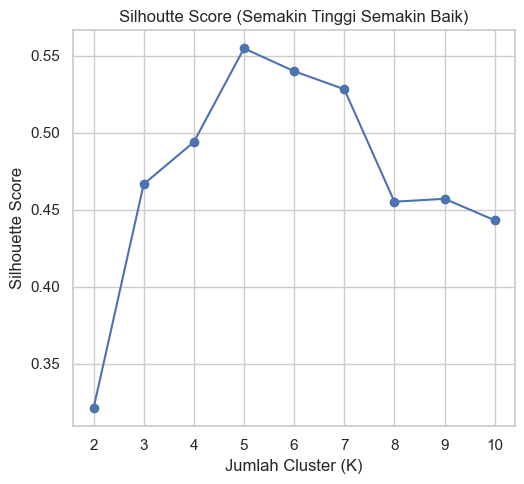

In [21]:
# 4. Visualisasi Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='o', linestyle='-', color='b')
plt.title('Silhoutte Score (Semakin Tinggi Semakin Baik)')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)

plt.tight_layout()
plt.show

##### Hasil
- Nilai naik terus dari K=2 sampai mencapai puncak tertinggi di K=5 dengan skor 0.5547.
- Setelah K=5, skornya langsung turun. Skor 0.55 itu sangat bagus untuk dataset rill (artinya jarak antar cluster cukup jelas dan padat)

In [22]:
# 5. Print hasil Silhouette dalam bentuk tabel
print("\n=== Silhoutte Score per K ===")
for k, score in zip(K_range, silhouette_scores):
    print(f"K = {k} : {score:.4f}")


=== Silhoutte Score per K ===
K = 2 : 0.3213
K = 3 : 0.4666
K = 4 : 0.4939
K = 5 : 0.5547
K = 6 : 0.5399
K = 7 : 0.5281
K = 8 : 0.4552
K = 9 : 0.4571
K = 10 : 0.4432


## K-Means Clustering & Profiling

### Clustering

In [23]:
# 1. Latih model finar dengan K=5
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_final.fit(X_scaled)

KMeans(n_clusters=5, n_init=10, random_state=42)

In [24]:
# 2. Masukkan label cluster ke dataframe asli
df['Cluster'] = kmeans_final.labels_

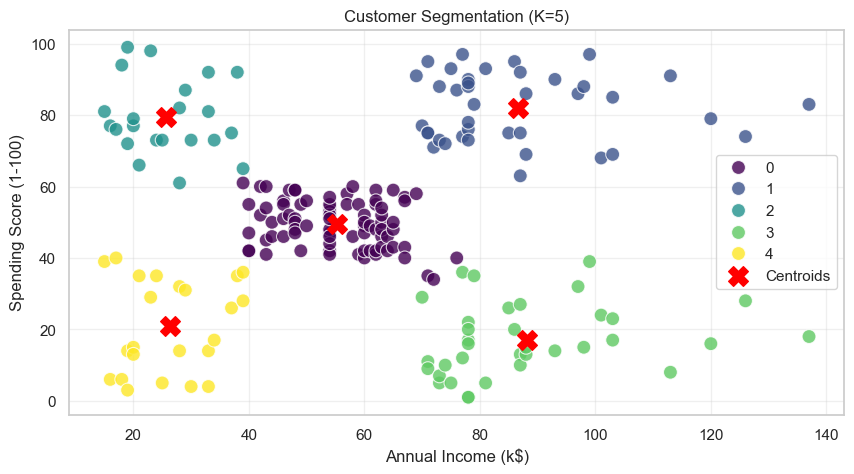

In [26]:
# 3. Visualisasi Hasil Clustering
plt.Figure(figsize=(10, 7))

# kita plot menggunakan data ASLI (bukan yang sudah di-scale) agar angka nya masuk akal
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100,
    alpha=0.8
)

# Menambahkan titik pusat cluster (Centroids) - Harus di-inverse transform dulu ke skala asli
centroids = scaler.inverse_transform(kmeans_final.cluster_centers_)
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    c= 'red', marker='X', s=200, label='Centroids'
)

plt.title('Customer Segmentation (K=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### interpretasi
- cluster 0(Warna ungu): The Average/ Standard Customers
income sedang (~50k), spending sedang (~50). Ini adalah pelanggan kebanyakan. Mereka belanja secukupnya, tidak terlalu boros tapi juga tidak pelit.

- cluster 1(warna biru gelap): The VIP/ Target utama
Income tinggi (>80k), spending tinggi (>70). ini adalah orang kaya yang suka belanja. Tim marketing harus memfokuskan strategi premium (diskon barang mewah, loyalty program) ke sini

- cluster 2(warna hijau tosca): The impulsive/ window shoppers
income rendah (~25k), Spending Tinggi (~80). Ini adalah orang yang pendapatannya pas-pasan tapi sangat suka jajan/belanja. Mereka mudah tergoda flash sale atau tren

- cluster 3 (warna hijau muda): The careful/ smart shoppers
Income tinggi (>80k), spending rendah (<30). ini orang kaya tapi sangat hemat. marketing perlu strategi khusus (misal: edukasi nilai investasi produk atau penawaran value for money) untuk membuat mereka membuka dompet.

- cluster 4(warna kuning): The frugal/ sensible
income rendah(~25k), spending rendah (~20). pelanggan yang sangat berhati-hati dengan uangnya. mereka hanya beli barang kebutuhan pokok.

### Profilling

In [27]:
# 1. Melihat statistik rata-rata per cluster
cluster_summary = df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1)
cluster_summary['Jumlah Pelanggan'] = df['Cluster'].value_counts()

# urutkan berdasarkan Income agar mudah dibaca
cluster_summary = cluster_summary.sort_values(by='Annual Income (k$)')

print("=== Ringkasan Profil Tiap Cluster ===")
print(cluster_summary)

# 2. Lihat komposisi Gender per cluster
print("\n=== Komposisi Gender per Cluster ===")
print(pd.crosstab(df['Cluster'], df['Gender']))

=== Ringkasan Profil Tiap Cluster ===
          Age  Annual Income (k$)  Spending Score (1-100)  Jumlah Pelanggan
Cluster                                                                    
2        25.3                25.7                    79.4                22
4        45.2                26.3                    20.9                23
0        42.7                55.3                    49.5                81
1        32.7                86.5                    82.1                39
3        41.1                88.2                    17.1                35

=== Komposisi Gender per Cluster ===
Gender   Female  Male
Cluster              
0            48    33
1            21    18
2            13     9
3            16    19
4            14     9


#### Interpretasi
1. Cluster 1: "The High Rollers" (VIP) – Income Tinggi, Spending Tinggi.
- Karakter: Pelanggan kaya yang tidak ragu belanja. Umur ralatif muda (32 tahun)
- Aksi: Target utama untuk produk premium, program loyalitas (membership VIP), dan early access untuk barang baru. Jangan beri diskon murah, beri exclusive experience.

2. Cluster 3: "The Smart Savers" – Income Tinggi, Spending Rendah.
- Karakter: Punya uang banyak tapi sangat berhati-hati (hemat). Umur lebih matang (41 tahun).
- Aksi: Berikan edukasi value for money (misal: kualitas barang yang awet). Tawarkan promo investasi atau bundling produk bernilai tinggi.

3. Cluster 2: "The Impulse Buyers" – Income Rendah, Spending Tinggi.
- Karakter: Anak muda (25 tahun) yang sangat konsumtif. Uang habis untuk jajan/belanja.
- Aksi: Sasaran empuk untuk Flash Sale, diskon kilat, paylater, dan promosi berbasis tren (FOMO).

4. Cluster 4: "The Frugal Shoppers" – Income Rendah, Spending Rendah.
- Karakter: Pelanggan hemat yang hanya beli kebutuhan pokok.
- Aksi: Tawarkan produk kebutuhan sehari-hari (sembako) dengan harga murah, atau program cashback untuk menghemat pengeluaran mereka.

5. Cluster 0: "The Averages" – Income Sedang, Spending Sedang.
- Karakter: Mayoritas pelanggan mal (81 orang). Perilaku belanja standar.
- Aksi: Pelanggan ini menjaga cashflow mal. Berikan promo umum, voucher belanja, atau event musiman agar mereka tetap sering datang.